## Anisotropy function fit sandbox

In [1]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "/Users/seanmullane/Desktop/Research_2025/modulated_shielding")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

from scipy.optimize import curve_fit
from scipy.interpolate import RegularGridInterpolator

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

In [2]:
# Load (r, theta, F) data
r_t_f = np.genfromtxt("anisotropy_func_values.txt", delimiter=" ")

r = r_t_f[:,0]
t = r_t_f[:,1]
F = r_t_f[:,2]

### Numpy lstsq() method

In [3]:
# not going to lie, vibe coding this from ChatGPT
# constructing third-degree polynomial fit for testing
A = np.column_stack((np.ones_like(r), r, t, r**2, r*t, t**2, r**3, (r**2)*t, r*(t**2), t**3))

X, res, __, __ = np.linalg.lstsq(A, F)
print(X)
print(res)

[ 6.97094812e-01 -2.86314944e-02  6.75917990e-03  9.69249612e-03
 -3.62797172e-04 -1.08412611e-05 -5.91259628e-04  1.25486212e-06
  2.02949129e-06 -1.71999433e-07]
[2.92935696]


In [4]:
# construct F(r, theta)
def F_predicted(r, theta, X):
    return X[0] + X[1]*r + X[2]*theta + X[3]*r**2 + X[4]*r*theta + X[5]*theta**2 + X[6]*(r**3) + X[7]*(r**2)*t + X[8]*r*(t**2) + X[9]*(t**3)

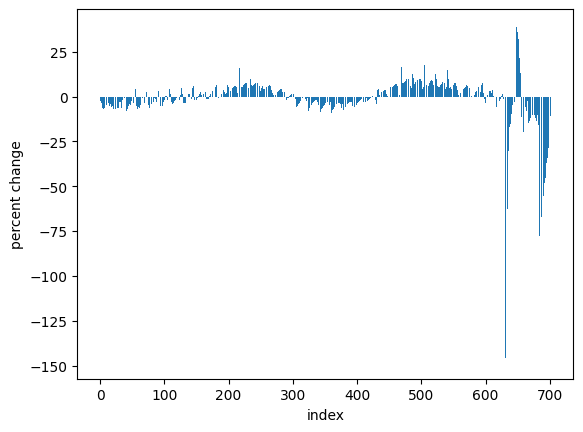

In [5]:
# run the above function with training data and check the percent difference from actual values
test_data = F_predicted(r, t, X)
delta = ((F - test_data)/F)*100
#print(delta)

# plot for debugging
x = np.arange(0, 702)
fig, ax = plt.subplots()
ax.bar(x, delta)
ax.set_xlabel('index')
ax.set_ylabel('percent change')
plt.show()

#### Scipy curve_fit() method

In [6]:
# construct independent variable input
x_data = np.vstack((r,t))

# note change in notation from above! X from parameter matrix to input matrix
def F_degree2(X, p0, p1, p2, p3, p4, p5):
    return p0 + p1*X[0,:] + p2*X[1,:] + p3*X[0,:]**2 + p4*X[0,:]*X[1,:] + p5*X[1,:]**2

def F_exp(X, a, b, c, d, e):
    return a*np.exp(-b * X[0,:]) + c*np.exp(-d * X[1,:]) + e

def F_sin(X, a, b, c, d, e):
    return a*np.sin(b*X[0,:]) + c*np.sin(d*X[1,:]) + e

def F_osc(X, a, b, c, d, e, f, g, h, i, j, k, l, m, n, z):
    r = X[0,:]
    t = X[1,:]
    return z + a*r + b*t + c*r*t + d*np.sin(e*r) + f*np.cos(g*r) + h*np.sin(i*t) + j*np.cos(k*t) + l*np.sin(m*r + n*t)

def F_osc_simple(X, a, d, e, f, g, h, i, j, k):
    r = X[0,:]
    t = X[1,:]
    return a + d*np.sin(e*r) + f*np.cos(g*r) + h*np.sin(i*t) + j*np.cos(k*t)
                                            
popt, pcov = curve_fit(F_osc_simple, x_data, F)
# check condition number of covariance matrix
print(popt)
print(np.linalg.cond(pcov))
print(np.diag(pcov))

[ 0.79356042 -0.0434507   1.11338906  0.02878705  0.80252279  0.004973
  0.97414876 -0.01661496  1.01603923]
393.5058997878652
[4.88453937e-05 1.62154876e-04 3.77735592e-03 1.41025660e-04
 6.55694758e-03 9.31356257e-05 3.98122311e-04 9.52604278e-05
 3.39209257e-05]


0.16335207106755925


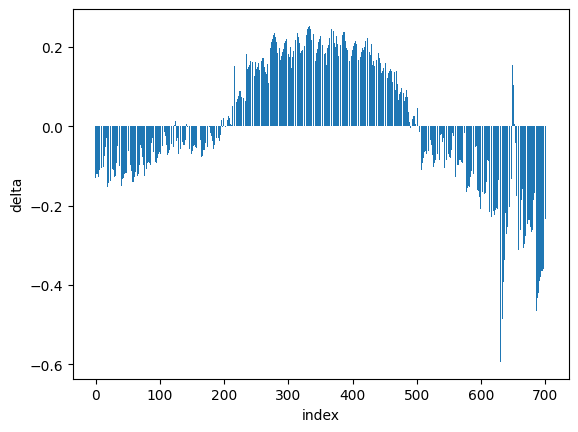

In [7]:
# let's plot the percent difference to compare to above
test_data_scipy = F_osc_simple(x_data, *popt)
delta = (F - test_data_scipy)

# calculate RMSE
rmse = np.sqrt(np.mean(delta**2))
print(rmse)

# degree 2 = 0.07
# exp = 0.158
# sin = 0.164
# osc = 0.158
# osc_simple = 0.163

# plot for debugging
x = np.arange(0, 702)
fig2, ax2 = plt.subplots()
ax2.bar(x, delta)
ax2.set_xlabel('index')
ax2.set_ylabel('delta')
plt.show()

### Let's try the SciPy interpolation function on a grid!
Who knows, maybe it will work this time.

In [8]:
# load the proper arrays
F_r = np.genfromtxt("F_r.txt")
F_theta = np.genfromtxt("F_theta.txt")
F_values = np.genfromtxt("F_values.txt")

# generate the interpolation
interp = RegularGridInterpolator((F_theta, F_r), F_values)

In [13]:
# test the interpolation
thetav, rv = np.meshgrid(F_theta, F_r, indexing='ij')
test_interp = interp((thetav, rv))
print(np.shape(test_interp)) # first index = angle, second index = radius

residual = test_interp.flatten() - F_values.flatten()
#print(residual) # this array is all zeroes, indicating that interpolator correctly handles test data input

# plot for debugging
x3 = np.arange(0, 702)
#fig3, ax3 = plt.subplots()
#ax3.bar(x3, residual)
#ax3.set_xlabel('index')
#ax3.set_ylabel('delta')
#plt.show()

(39, 18)


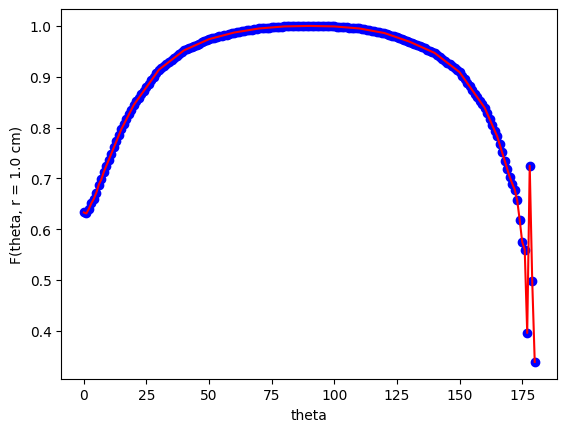

In [11]:
# since the interpolator gives residual = 0, let's plot holding radius constant and compare
# plot F_value vs theta for r = 1.0 cm --> index = 5 in F_values
x = np.arange(0, 181, 1)
r = np.ones(181)
values_guess = interp((x, r))

values_actual = F_values[:,5]

fig4, ax4 = plt.subplots() 
ax4.scatter(x, values_guess, color='blue')
ax4.plot(F_theta, values_actual, color='red')
ax4.set_xlabel('theta')
ax4.set_ylabel('F(theta, r = 1.0 cm)')
plt.show()

# it looks like this works pretty well - the spline and the actual essentially overlap

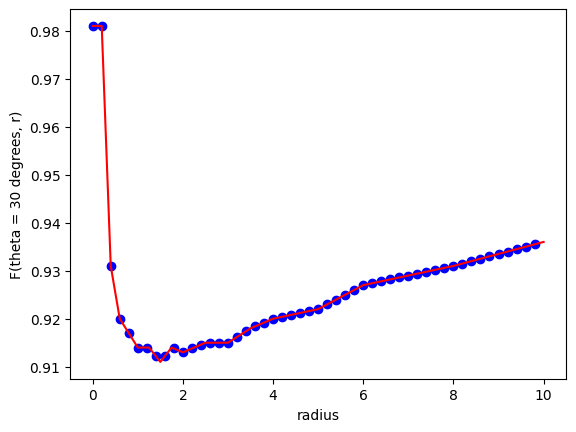

In [19]:
# setting up another plot holding theta constant for comparison
# plot F_value vs r for theta = 30 degrees
x = np.arange(0, 10, 0.2)
theta = np.ones(50)*30

values_guess = interp((theta, x))
values_actual = F_values[13,:]

fig5, ax5 = plt.subplots() 
ax5.scatter(x, values_guess, color='blue')
ax5.plot(F_r, values_actual, color='red')
ax5.set_xlabel('radius')
ax5.set_ylabel('F(theta = 30 degrees, r)')
plt.show()